# Notebook 03 – Mô hình hóa, Tinh chỉnh & Đánh giá dự báo (Modeling & Evaluation)

**Nội dung thực hiện (bám sát Mục 3.5 & 4.3 Báo cáo):**
1. **Chia tập theo trình tự thời gian:** Đọc `clean_data.parquet` và `clean_data.json`, tách **Train** (`< 2018-01-01`) và **Test** (`>= 2018-01-01`), tuyệt đối không xáo trộn ngẫu nhiên.
2. **Nghiên cứu cắt giảm (Ablation Study – RQ1 & RQ2):** Đối sánh 5 phương pháp (*Seasonal Naive Baseline*, *Linear Regression*, *Ridge Regression*, *Random Forest*, *XGBoost*) trên cả **Bộ đặc trưng A** (23 biến – dài hạn) và **Bộ đặc trưng B** (26 biến – ngắn hạn có biến trễ) qua 4 độ đo **MAE, RMSE, MAPE ($y_i > 100$), $R^2$**.
3. **Tinh chỉnh siêu tham số & Phân tích lỗi:** Tối ưu `XGBoost` bằng `RandomizedSearchCV` kết hợp `TimeSeriesSplit(n_splits=4)` trên tập Train; trực quan hóa dự báo 7 ngày, độ quan trọng đặc trưng, phân rã sai số (theo giờ, ngày lễ, thời tiết, Top sai số lớn nhất) và lưu model bằng `joblib`.

In [1]:
import json
import os
import warnings
warnings.filterwarnings("ignore")
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid", font_scale=1.05)
SEED = 42
DATA_DIR = os.path.join("..", "data", "processed")
RESULTS_DIR = os.path.join("..", "results")
FIGURES_DIR = os.path.join("..", "figures")
MODELS_DIR = os.path.join("..", "models")
for d in [RESULTS_DIR, FIGURES_DIR, MODELS_DIR]:
    os.makedirs(d, exist_ok=True)

# 1. Đọc dữ liệu sạch & cấu hình đặc trưng từ Note 02
df = pd.read_parquet(os.path.join(DATA_DIR, "clean_data.parquet"))
with open(os.path.join(DATA_DIR, "clean_data.json"), encoding="utf-8") as f:
    cfg = json.load(f)

FEATURES_A = cfg["FEATURES_A"]
FEATURES_B = cfg["FEATURES_B"]
TEST_START = pd.Timestamp(cfg["TEST_START"])

df = df.sort_values("date_time").reset_index(drop=True)
train_df = df[df["date_time"] < TEST_START].reset_index(drop=True)
test_df = df[df["date_time"] >= TEST_START].reset_index(drop=True)
y_train = train_df["traffic_volume"].to_numpy(dtype=float)
y_test = test_df["traffic_volume"].to_numpy(dtype=float)

# 2. Hàm tính 4 độ đo chuẩn Hồi quy (MAPE lọc y_i > 100 xe/giờ theo Mục 2.5.1)
def danh_gia(y_true, y_pred):
    mask = y_true > 100
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    return {
        "MAE": round(float(mean_absolute_error(y_true, y_pred)), 2),
        "RMSE": round(float(root_mean_squared_error(y_true, y_pred)), 2),
        "MAPE (%)": round(float(mape), 2),
        "R2": round(float(r2_score(y_true, y_pred)), 4),
    }

print(f"Train (< {cfg['TEST_START']}): {len(train_df):,} dòng | Test (>= {cfg['TEST_START']}): {len(test_df):,} dòng")
print(f"Bộ đặc trưng A: {len(FEATURES_A)} biến | Bộ đặc trưng B: {len(FEATURES_B)} biến")

Train (< 2018-01-01): 28,353 dòng | Test (>= 2018-01-01): 6,480 dòng
Bộ đặc trưng A: 23 biến | Bộ đặc trưng B: 26 biến


In [2]:
# Đối sánh 5 phương pháp trên cả Bộ A (không lag) và Bộ B (có lag) - Trả lời RQ1 & RQ2
def khoi_tao_models():
    return {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=10.0, random_state=SEED)),
        "Random Forest": RandomForestRegressor(
            n_estimators=100, max_depth=12, max_features=1/3, random_state=SEED, n_jobs=-1
        ),
        "XGBoost": XGBRegressor(
            n_estimators=100, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1
        ),
    }

ket_qua = []
predictions_B = {}
models_B = {}

# 1. Mô hình cơ sở Seasonal Naive Baseline: y_hat(t) = lag_24h
pred_naive = test_df["lag_24h"].to_numpy(dtype=float)
ket_qua.append({"Bộ đặc trưng": "Baseline", "Model": "Seasonal Naive (lag_24h)", **danh_gia(y_test, pred_naive)})
predictions_B["Baseline (Seasonal Naive)"] = pred_naive

# 2. Huấn luyện & đánh giá 4 mô hình học máy trên Bộ A và Bộ B
for ten_bo, cols in [("Bộ A (23 biến - Lịch & Thời tiết)", FEATURES_A),
                     ("Bộ B (26 biến - Bộ A + Lag)", FEATURES_B)]:
    X_tr, X_te = train_df[cols], test_df[cols]
    for ten_m, model in khoi_tao_models().items():
        model.fit(X_tr, y_tr := y_train)
        pred = model.predict(X_te)
        ket_qua.append({"Bộ đặc trưng": ten_bo, "Model": ten_m, **danh_gia(y_test, pred)})
        if "Bộ B" in ten_bo:
            predictions_B[ten_m] = pred
            models_B[ten_m] = model

eval_df = pd.DataFrame(ket_qua)
eval_df.to_csv(os.path.join(RESULTS_DIR, "note03_evaluation_metrics.csv"), index=False, encoding="utf-8-sig")
display(eval_df)

,Bộ đặc trưng,Model,MAE,RMSE,MAPE (%),R2
0,Baseline,Seasonal Naive (lag_24h),568.37,1032.94,25.08,0.7251
1,Bộ A (23 biến - Lịch & Thời tiết),Linear Regression,631.51,858.01,43.08,0.8103
2,Bộ A (23 biến - Lịch & Thời tiết),Ridge Regression,631.54,858.02,43.10,0.8103
3,Bộ A (23 biến - Lịch & Thời tiết),Random Forest,229.66,381.66,10.08,0.9625
4,Bộ A (23 biến - Lịch & Thời tiết),XGBoost,223.66,371.72,10.05,0.9644
5,Bộ B (26 biến - Bộ A + Lag),Linear Regression,353.76,475.66,21.18,0.9417
6,Bộ B (26 biến - Bộ A + Lag),Ridge Regression,353.61,475.92,21.17,0.9416
7,Bộ B (26 biến - Bộ A + Lag),Random Forest,143.95,223.65,5.83,0.9871
8,Bộ B (26 biến - Bộ A + Lag),XGBoost,143.49,221.75,5.84,0.9873


In [3]:
# Tinh chỉnh siêu tham số XGBoost bằng RandomizedSearchCV + TimeSeriesSplit(n_splits=4) trên tập Train (Mục 3.5.3)
tscv = TimeSeriesSplit(n_splits=4)
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=SEED, n_jobs=-1, tree_method="hist"),
    param_distributions=param_dist,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=SEED,
    refit=True,  # Tự động huấn luyện lại cấu hình tốt nhất trên toàn bộ tập Train
)
search.fit(train_df[FEATURES_B], y_train)

best_xgb_B = search.best_estimator_
pred_best_B = best_xgb_B.predict(test_df[FEATURES_B])
predictions_B["XGBoost (Tuned)"] = pred_best_B

# Tổng hợp bảng kết quả tinh chỉnh và lưu CSV
cv_res = pd.DataFrame(search.cv_results_)
bang_tuning = cv_res[[
    "param_n_estimators", "param_max_depth", "param_learning_rate",
    "param_subsample", "param_colsample_bytree", "mean_test_score", "rank_test_score"
]].copy()
bang_tuning["CV_RMSE_mean"] = (-bang_tuning["mean_test_score"]).round(2)
bang_tuning = bang_tuning.drop(columns=["mean_test_score"]).sort_values("rank_test_score").reset_index(drop=True)
bang_tuning.to_csv(os.path.join(RESULTS_DIR, "table_4_2_xgboost_tuning.csv"), index=False, encoding="utf-8-sig")

print("Bộ siêu tham số tốt nhất:", search.best_params_)
print("Kết quả XGBoost (Tuned) trên tập Test:", danh_gia(y_test, pred_best_B))
display(bang_tuning.head(10))

Bộ siêu tham số tốt nhất: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Kết quả XGBoost (Tuned) trên tập Test: {'MAE': 138.88, 'RMSE': 217.05, 'MAPE (%)': 5.61, 'R2': 0.9879}


,param_n_estimators,param_max_depth,param_learning_rate,param_subsample,param_colsample_bytree,rank_test_score,CV_RMSE_mean
0,300,8,0.05,0.8,0.8,1,252.87
1,100,8,0.05,0.8,0.8,2,253.11
2,200,8,0.05,0.8,1.0,3,253.17
3,300,6,0.05,0.8,0.8,4,253.72
4,300,6,0.05,0.8,1.0,5,254.00
5,100,8,0.10,0.8,0.8,6,254.37
6,100,8,0.10,1.0,0.8,7,254.39
7,300,6,0.05,1.0,1.0,8,254.79
8,200,6,0.10,0.8,1.0,9,254.99
9,100,8,0.05,1.0,1.0,10,255.06


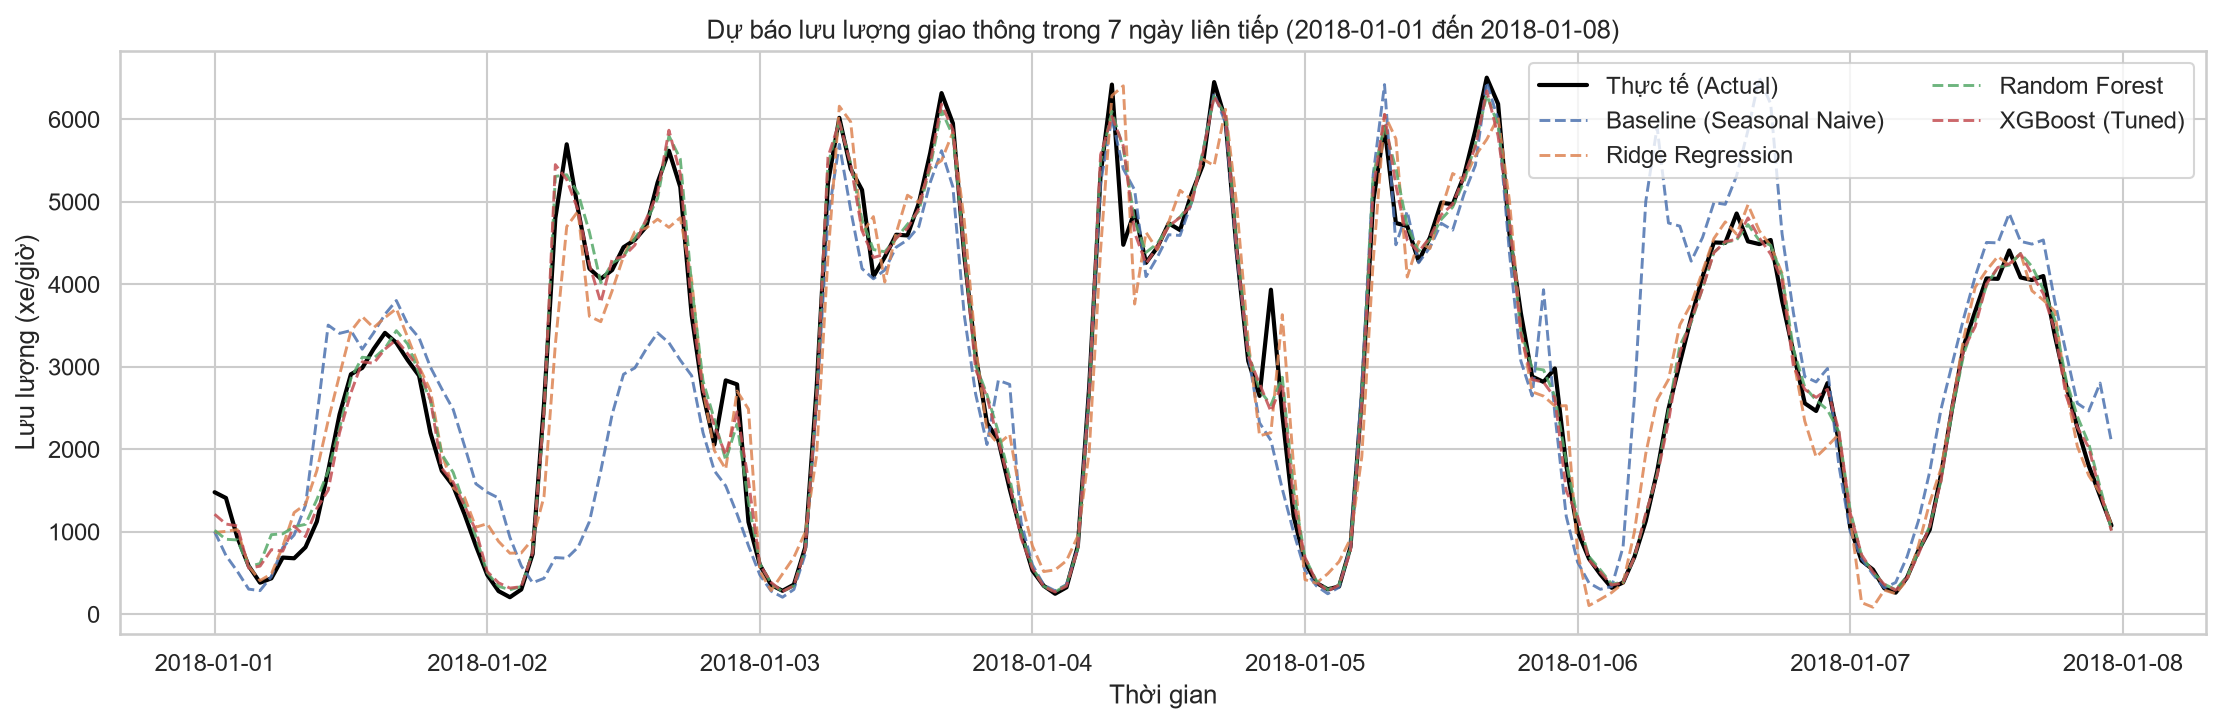

In [4]:
# Trực quan hóa dự báo 7 ngày liên tiếp đầu năm 2018 (01/01/2018 -> 08/01/2018)
mask_7d = test_df["date_time"] < (test_df["date_time"].iloc[0] + pd.Timedelta(days=7))
dt_7d = test_df.loc[mask_7d, "date_time"]

plt.figure(figsize=(15, 5))
plt.plot(dt_7d, y_test[mask_7d], label="Thực tế (Actual)", color="black", linewidth=2.0)
for ten in ["Baseline (Seasonal Naive)", "Ridge Regression", "Random Forest", "XGBoost (Tuned)"]:
    plt.plot(dt_7d, predictions_B[ten][mask_7d], label=ten, linestyle="--", linewidth=1.4, alpha=0.85)

plt.title("Dự báo lưu lượng giao thông trong 7 ngày liên tiếp (2018-01-01 đến 2018-01-08)")
plt.xlabel("Thời gian")
plt.ylabel("Lưu lượng (xe/giờ)")
plt.legend(loc="upper right", ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "note03_forecast_7_days.png"), dpi=250, bbox_inches="tight")
plt.show()

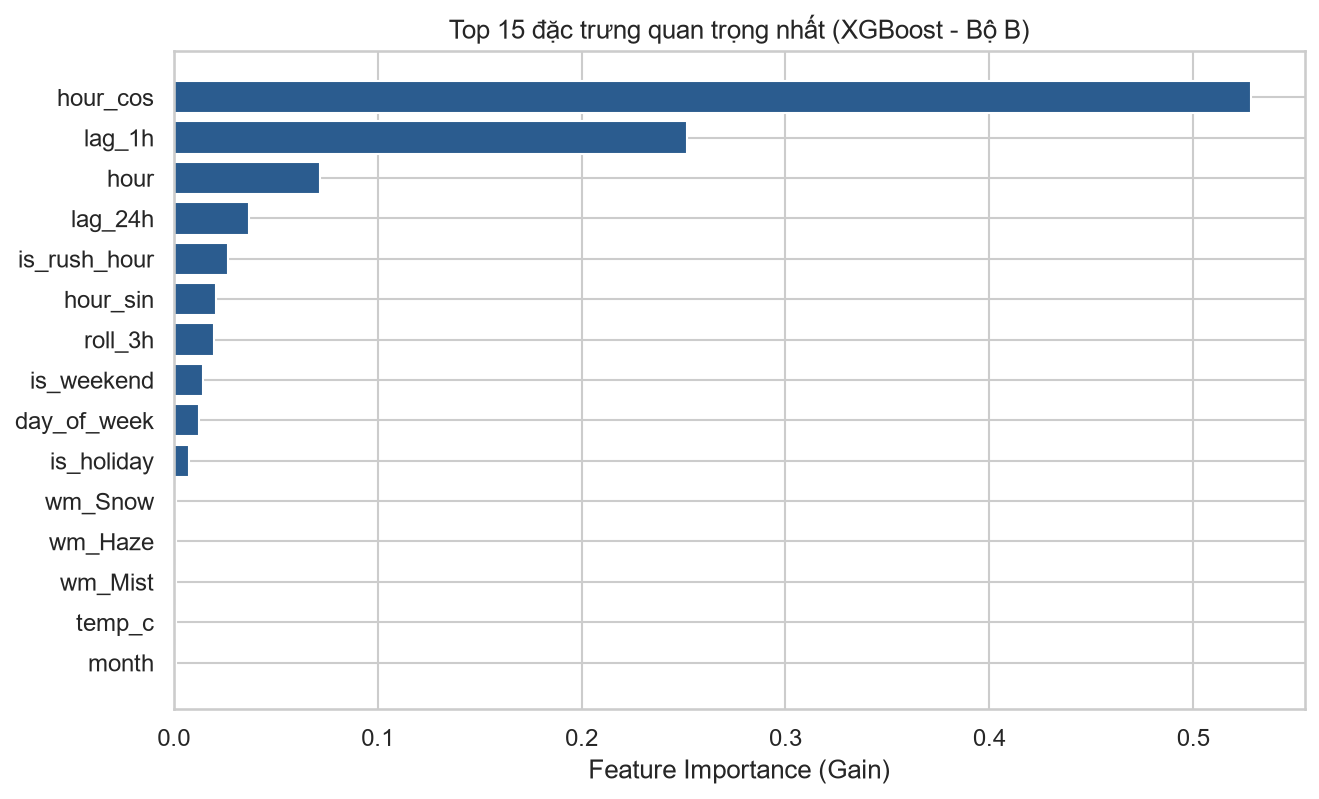

In [5]:
# Mức độ quan trọng của Top 15 đặc trưng trên mô hình XGBoost tốt nhất
fi = pd.Series(best_xgb_B.feature_importances_, index=FEATURES_B).sort_values().tail(15)

plt.figure(figsize=(9, 5.5))
plt.barh(fi.index, fi.values, color="#2b5c8f")
plt.title("Top 15 đặc trưng quan trọng nhất (XGBoost - Bộ B)")
plt.xlabel("Feature Importance (Gain)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "hinh_4_2_feature_importance.png"), dpi=250, bbox_inches="tight")
plt.show()

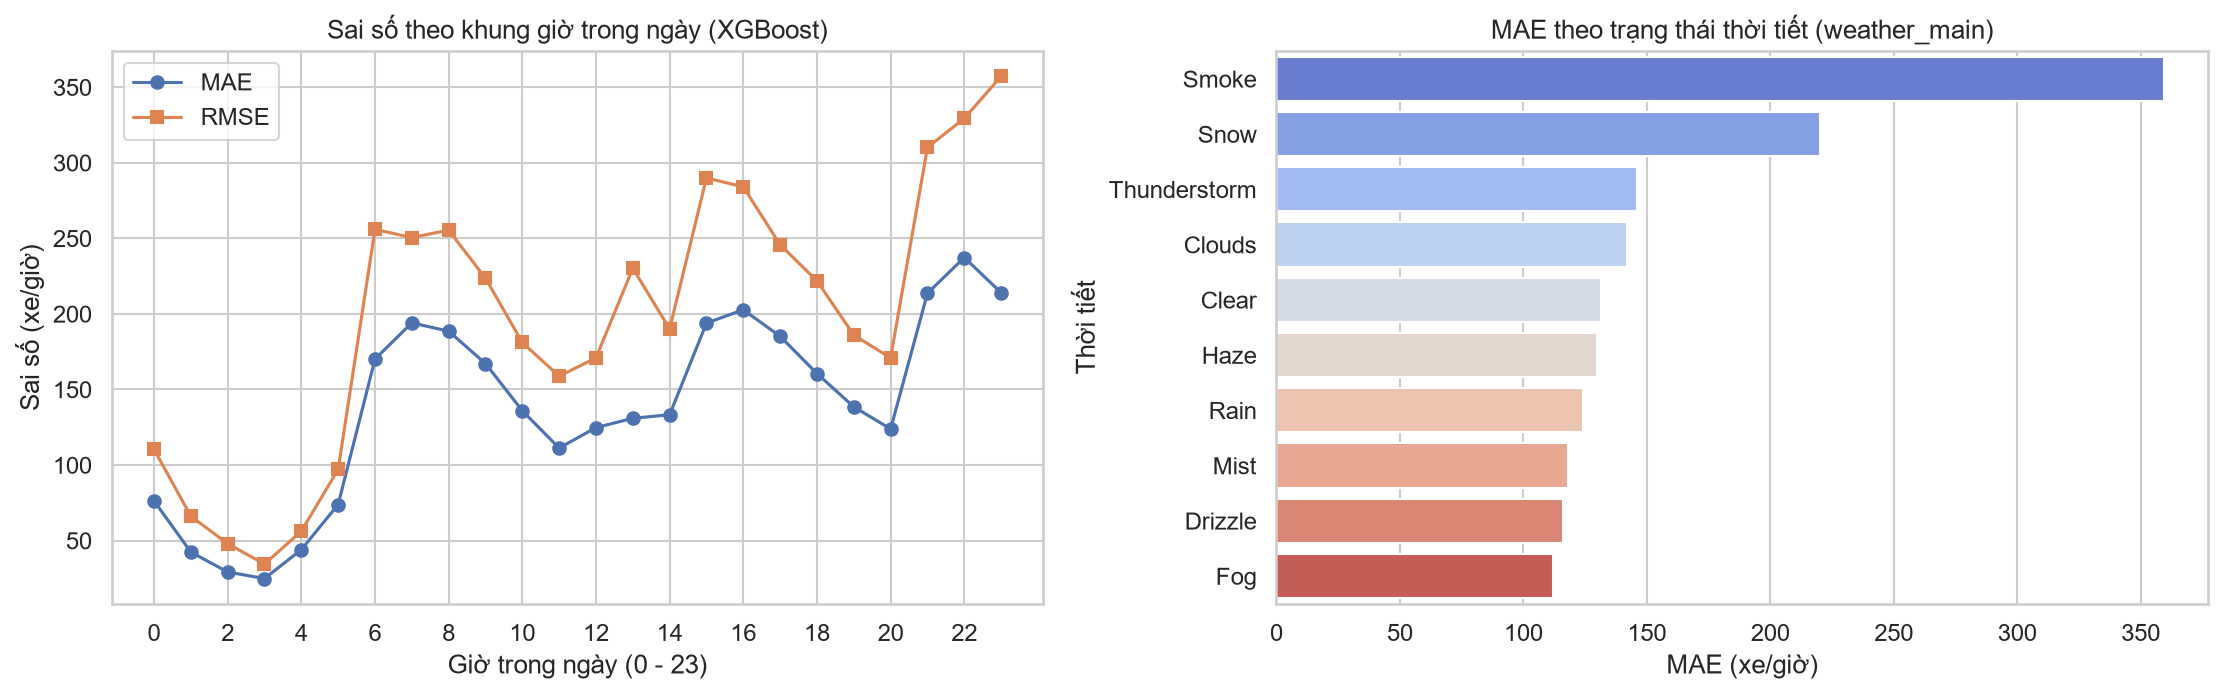

,is_holiday,so_mau,MAE,RMSE
0,Ngày thường,6316,138.56,217.57
1,Ngày lễ,164,151.05,196.31


,date_time,weather_main,temp_c,snow_1h,is_holiday,actual,pred,abs_error
3320,2018-05-21 13:00:00,Clouds,17.5,0.0,0,2040.0,4838.000000,2798.0
399,2018-01-17 15:00:00,Clear,-3.6,0.0,0,3271.0,5615.799805,2344.8
400,2018-01-17 16:00:00,Clear,-2.8,0.0,0,5287.0,3435.600098,1851.4
6455,2018-09-29 23:00:00,Clouds,7.2,0.0,0,3856.0,2017.199951,1838.8
6431,2018-09-28 23:00:00,Clear,4.3,0.0,0,3544.0,1824.800049,1719.2


In [6]:
# Phân tích lỗi chuyên sâu trên tập Test theo 4 chiều (Mục 3.5.4 & 5.2 Báo cáo)
err_df = test_df[["date_time", "hour", "is_holiday", "weather_main", "temp_c", "rain_1h", "snow_1h"]].copy()
err_df["actual"] = y_test
err_df["pred"] = np.round(pred_best_B, 1)
err_df["abs_error"] = np.abs(y_test - pred_best_B)
err_df["sq_error"] = (y_test - pred_best_B) ** 2

def bang_sai_so(col):
    return (err_df.groupby(col, as_index=False)
            .agg(so_mau=("abs_error", "size"),
                 MAE=("abs_error", "mean"),
                 RMSE=("sq_error", lambda s: float(np.sqrt(np.mean(s)))))
            .round(2))

hourly_err = bang_sai_so("hour")
holiday_err = bang_sai_so("is_holiday").replace({"is_holiday": {0: "Ngày thường", 1: "Ngày lễ"}})
weather_err = bang_sai_so("weather_main").sort_values("MAE", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(hourly_err["hour"], hourly_err["MAE"], marker="o", label="MAE")
axes[0].plot(hourly_err["hour"], hourly_err["RMSE"], marker="s", label="RMSE")
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_title("Sai số theo khung giờ trong ngày (XGBoost)")
axes[0].set_xlabel("Giờ trong ngày (0 - 23)")
axes[0].set_ylabel("Sai số (xe/giờ)")
axes[0].legend()

sns.barplot(data=weather_err, x="MAE", y="weather_main", hue="weather_main", palette="coolwarm", legend=False, ax=axes[1])
axes[1].set_title("MAE theo trạng thái thời tiết (weather_main)")
axes[1].set_xlabel("MAE (xe/giờ)")
axes[1].set_ylabel("Thời tiết")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "note03_error_analysis_hour_weather.png"), dpi=250, bbox_inches="tight")
plt.show()

top5_err = err_df.sort_values("abs_error", ascending=False).head(5)[["date_time", "weather_main", "temp_c", "snow_1h", "is_holiday", "actual", "pred", "abs_error"]].copy()
top5_err[["temp_c", "pred", "abs_error"]] = top5_err[["temp_c", "pred", "abs_error"]].round(1)
display(holiday_err)
display(top5_err)

In [7]:
# Đóng gói mô hình bằng Joblib (Mục 3.7.2: Lưu cả model Bộ B tốt nhất và model Bộ A kèm ngưỡng P50, P85 cho Demo Gradio)
p50 = float(np.percentile(y_train, 50))
p85 = float(np.percentile(y_train, 85))

best_xgb_A = XGBRegressor(**search.best_params_, random_state=SEED, n_jobs=-1)
best_xgb_A.fit(train_df[FEATURES_A], y_train)
metrics_A = danh_gia(y_test, best_xgb_A.predict(test_df[FEATURES_A]))

joblib.dump({
    "model_name": "XGBoost (Tuned - Bộ B)",
    "model": best_xgb_B,
    "features": FEATURES_B,
    "p50": p50,
    "p85": p85,
    "metrics": danh_gia(y_test, pred_best_B),
}, os.path.join(MODELS_DIR, "best_model_xgboost.joblib"))

joblib.dump({
    "model_name": "XGBoost (Tuned - Bộ A Demo)",
    "model": best_xgb_A,
    "features": FEATURES_A,
    "p50": p50,
    "p85": p85,
    "metrics": metrics_A,
}, os.path.join(MODELS_DIR, "demo_model_xgb_A.joblib"))

print(f"Ngưỡng cảnh báo từ tập Train: P50 = {p50:.0f} xe/giờ | P85 = {p85:.0f} xe/giờ")
print("Kết quả XGBoost (Tuned - Bộ A cho Demo):", metrics_A)
print("Đã lưu thành công best_model_xgboost.joblib và demo_model_xgb_A.joblib vào ../models/")

Ngưỡng cảnh báo từ tập Train: P50 = 3356 xe/giờ | P85 = 5484 xe/giờ
Kết quả XGBoost (Tuned - Bộ A cho Demo): {'MAE': 224.36, 'RMSE': 370.66, 'MAPE (%)': 9.86, 'R2': 0.9646}
Đã lưu thành công best_model_xgboost.joblib và demo_model_xgb_A.joblib vào ../models/
